# Module 10 · Servo và synchro (EASA M04 SM03 + giáo trình servo)

In [1]:
import numpy as np, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Điện áp ba cuộn stato theo góc rôto

Vmax per coil = 52.3 V
rotor   0 deg: S-coil voltages = [ 52.3 -26.1 -26.1]  (sum = -0.0)
rotor  30 deg: S-coil voltages = [ 45.3   0.  -45.3]  (sum = -0.0)
rotor  60 deg: S-coil voltages = [ 26.1  26.1 -52.3]  (sum = 0.0)
rotor  90 deg: S-coil voltages = [  0.   45.3 -45.3]  (sum = 0.0)
rotor 120 deg: S-coil voltages = [-26.1  52.3 -26.1]  (sum = 0.0)


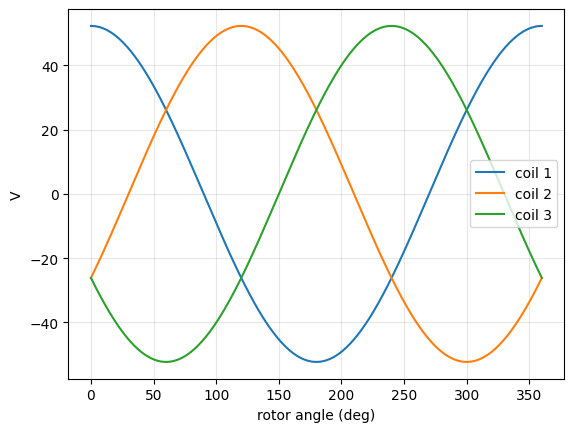

In [2]:
Vr = 115.0; Vmax = Vr/2.2     # SV p.14: 2.2:1 step-down, ~52 V
th = np.radians(np.arange(0, 361, 30)); phases = np.radians([0, 120, 240])
print(f"Vmax per coil = {Vmax:.1f} V")
for t in (0, 30, 60, 90, 120):
    v = Vmax*np.cos(np.radians(t) - phases); print(f"rotor {t:>3} deg: S-coil voltages = {np.round(v,1)}  (sum = {v.sum():.1f})")
ang = np.linspace(0, 360, 361)
for k, ph in enumerate(phases): plt.plot(ang, Vmax*np.cos(np.radians(ang)-ph), label=f"coil {k+1}")
plt.legend(); plt.xlabel("rotor angle (deg)"); plt.ylabel("V"); plt.grid(alpha=.3); plt.show()

**Nhận xét:** mỗi cuộn đạt tối đa ≈ 52,3 V khi rôto thẳng hàng với nó; tại mọi góc ba điện áp có tổng bằng không (mô hình lý tưởng) và cặp giá trị xác định duy nhất góc — vì thế ba dây đủ để truyền góc.

## 2. Điện áp sai số của CT và độ nhạy gần null

misalignment  0 deg: error =   0.00 V (small-angle approx   0.00 V)
misalignment  1 deg: error =   0.96 V (small-angle approx   0.96 V)
misalignment  5 deg: error =   4.79 V (small-angle approx   4.80 V)
misalignment 10 deg: error =   9.55 V (small-angle approx   9.60 V)
misalignment 30 deg: error =  27.50 V (small-angle approx  28.80 V)
misalignment 60 deg: error =  47.63 V (small-angle approx  57.60 V)
misalignment 90 deg: error =  55.00 V (small-angle approx  86.39 V)


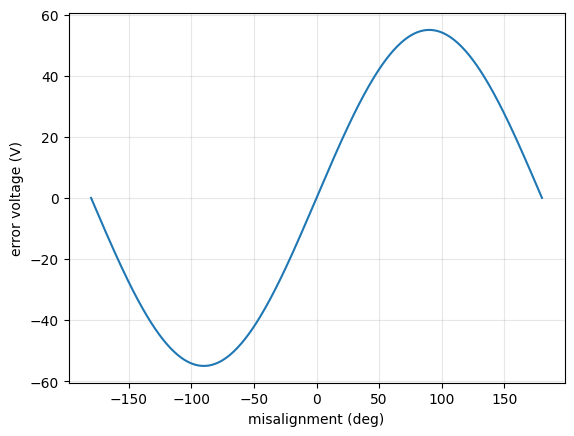

In [3]:
Emax = 55.0     # SV p.35: maximum 55 V when the CT rotor is parallel to the stator field
for d in (0, 1, 5, 10, 30, 60, 90): print(f"misalignment {d:>2} deg: error = {Emax*np.sin(np.radians(d)):6.2f} V (small-angle approx {Emax*np.radians(d):6.2f} V)")
ang = np.linspace(-180, 180, 361); plt.plot(ang, Emax*np.sin(np.radians(ang))); plt.xlabel("misalignment (deg)"); plt.ylabel("error voltage (V)"); plt.grid(alpha=.3); plt.show()

**Nhận xét:** mô hình Verr = 55·sin(Δθ) cho 0,96 V ở 1°, 4,79 V ở 5°, và 55 V ở 90°; gần null độ dốc ≈ 0,96 V/độ nên CT phát hiện rất nhạy độ lệch nhỏ; phép xấp xỉ góc nhỏ sai dưới 1 % cho tới 10°. (Giá trị 55 V lấy từ ví dụ SV; quy luật sin là mô hình lý tưởng.)

## 3. Servo vận tốc: ví dụ của SV tr.71

first instant error = 4.50 V
after 60 steps: N = 30.00 rpm, error = 3.00 V
analytic: N = K*Vin/(2+K*t) = 30.00 rpm, error = 3.00 V


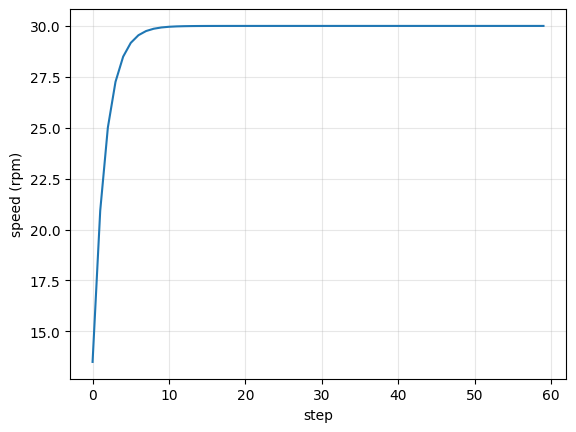

In [4]:
K, t, Vin = 10.0, 0.1, 9.0       # 10 rpm per volt of error, tach 0.1 V/rpm, control -9 V, R2=R3
N = 0.0; hist = []
for k in range(60):
    err = (Vin - t*N)/2           # sum point magnitude
    N += 0.3*(K*err - N)           # motor speed follows K*err with a first-order lag
    hist.append((N, err))
print(f"first instant error = {Vin/2:.2f} V")
print(f"after 60 steps: N = {hist[-1][0]:.2f} rpm, error = {hist[-1][1]:.2f} V")
print(f"analytic: N = K*Vin/(2+K*t) = {K*Vin/(2+K*t):.2f} rpm, error = {K*Vin/(2+K*t)/K:.2f} V")
plt.plot([h[0] for h in hist]); plt.xlabel("step"); plt.ylabel("speed (rpm)"); plt.grid(alpha=.3); plt.show()

**Nhận xét:** sai số ban đầu 4,5 V, tốc độ tiến đến 30 vòng/phút và sai số 3 V, đúng ví dụ của giáo trình; ở cân bằng vẫn còn sai số 3 V — đặc điểm của servo vận tốc.

## 4. Hunting và tắt dần của servo vị trí

no damping    : zeta = 0.05, simulated overshoot =  85.4 %, formula =  85.4 %
tach damping  : zeta = 0.70, simulated overshoot =   4.6 %, formula =   4.6 %
heavy damping : zeta = 1.20, simulated overshoot =   0.0 %, formula =   0.0 %


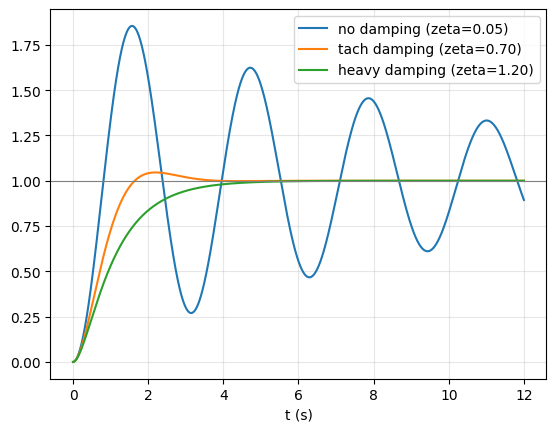

In [5]:
J, B, KtKp = 1.0, 0.2, 4.0      # inertia, friction, loop gain
wn = np.sqrt(KtKp/J)
dt = 1e-3; T = np.arange(0, 12, dt)
res = {}
for name, Kd in (("no damping", 0.0), ("tach damping", 2.6), ("heavy damping", 4.6)):
    z = (B + Kd)/(2*np.sqrt(KtKp*J)); th = 0.0; w = 0.0; y = []
    for _ in T:
        e = 1.0 - th; acc = (KtKp*e - Kd*w - B*w)/J; w += acc*dt; th += w*dt; y.append(th)
    y = np.array(y); res[name] = (z, (y.max()-1)*100); plt.plot(T, y, label=f"{name} (zeta={z:.2f})")
    print(f"{name:14s}: zeta = {z:.2f}, simulated overshoot = {max(0,(y.max()-1)*100):5.1f} %, formula = {(np.exp(-np.pi*z/np.sqrt(1-z*z))*100 if z<1 else 0):5.1f} %")
plt.axhline(1, color="gray", lw=.8); plt.legend(); plt.xlabel("t (s)"); plt.grid(alpha=.3); plt.show()

**Nhận xét:** không có tắt dần ζ = 0.05 và vượt quá khoảng 85 % rồi dao động kéo dài (hunting); tắt dần bằng hồi tiếp máy phát tốc đưa ζ lên 0.7 với vượt quá khoảng 4.6 %; tắt dần mạnh ζ = 1.2 không còn vượt quá — đúng tinh thần quá/thiếu tắt dần trong SV tr.73.